Average rentals by hour

In [46]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../bike+sharing+dataset/hour.csv")
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [47]:
import sys
print(sys.executable)

c:\Users\jacob\Machine Learning\bike_rentals_project\.venv\Scripts\python.exe


Visualization

In [48]:
df.shape

(17379, 17)

In [49]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


In [50]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [51]:
df.duplicated().sum()

np.int64(0)

In [52]:
df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


The descriptive statistics show that the dataset contains 17,379 hourly observations. Bike rental demand (cnt) ranges from 1 to 977 rentals per hour, with an average of approximately 189 and a median of 142. This indicates considerable variation in hourly demand. The weather-related variables are normalized, while approximately 68% of the observations represent working days. Overall, the descriptive statistics did not reveal any values that required additional preprocessing.

In [53]:
hourly_avg = df.groupby("hr")["cnt"].mean()
print(hourly_avg)


hr
0      53.898072
1      33.375691
2      22.869930
3      11.727403
4       6.352941
5      19.889819
6      76.044138
7     212.064649
8     359.011004
9     219.309491
10    173.668501
11    208.143054
12    253.315934
13    253.661180
14    240.949246
15    251.233196
16    311.983562
17    461.452055
18    425.510989
19    311.523352
20    226.030220
21    172.314560
22    131.335165
23     87.831044
Name: cnt, dtype: float64


average rentals in seasons

In [54]:
avg_season= df.groupby("season")["cnt"].mean()
print(avg_season)

season
1    111.114569
2    208.344069
3    236.016237
4    198.868856
Name: cnt, dtype: float64


average rentals weather conditions

In [55]:
avg_weather= df.groupby("weathersit")["cnt"].mean()
print(avg_weather)

weathersit
1    204.869272
2    175.165493
3    111.579281
4     74.333333
Name: cnt, dtype: float64


In [56]:
avg_weekday= df.groupby("weekday")["cnt"].mean()
print(avg_weekday)

weekday
0    177.468825
1    183.744655
2    191.238891
3    191.130505
4    196.436665
5    196.135907
6    190.209793
Name: cnt, dtype: float64


Column selection

In [57]:
features = [
    "season",
    "yr",
    "mnth",
    "hr",
    "holiday",
    "weekday",
    "workingday",
    "weathersit",
    "temp",
    "hum",
    "windspeed"
]

x = df[features].copy()
y= df["cnt"].copy()

x.head()
y.head()

0    16
1    40
2    32
3    13
4     1
Name: cnt, dtype: int64

instant was excluded because it's only a record identifier, while casual and registered were excluded because they directly make up the target cnt and would cause data leakage. dteday: We will use it to organise observations chronologically, but exclude the raw date from the initial model.
atemp: Highly correlated with temp, so we will exclude it initially to reduce redundancy.


Temperature vs Rental counts

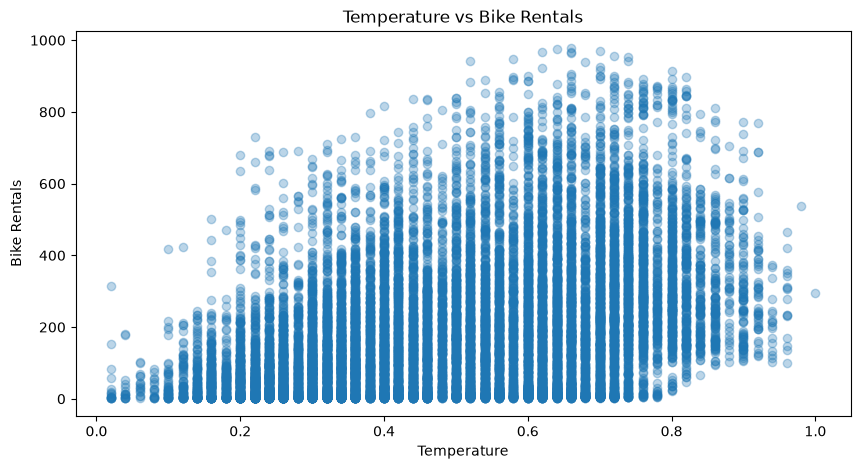

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.scatter(df["temp"], df["cnt"], alpha=0.3)

plt.title("Temperature vs Bike Rentals")
plt.xlabel("Temperature")
plt.ylabel("Bike Rentals")

plt.show()

Humidity vs Bike rentals

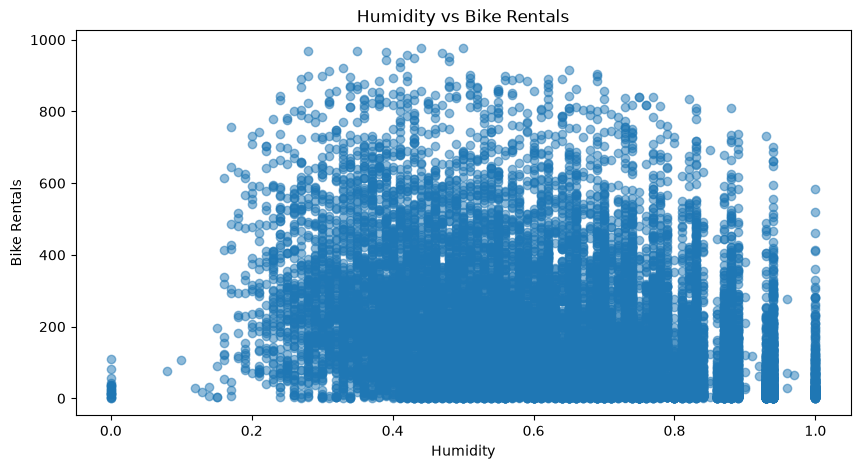

In [59]:
plt.figure(figsize=(10, 5))

plt.scatter(df["hum"], df["cnt"], alpha=0.5)
plt.title("Humidity vs Bike Rentals")
plt.xlabel("Humidity")
plt.ylabel("Bike Rentals")
plt.show()

weekday vs non working day

In [60]:
avg_workingdays = df.groupby("workingday")["cnt"].mean()
print(avg_workingdays)

workingday
0    181.405332
1    193.207754
Name: cnt, dtype: float64


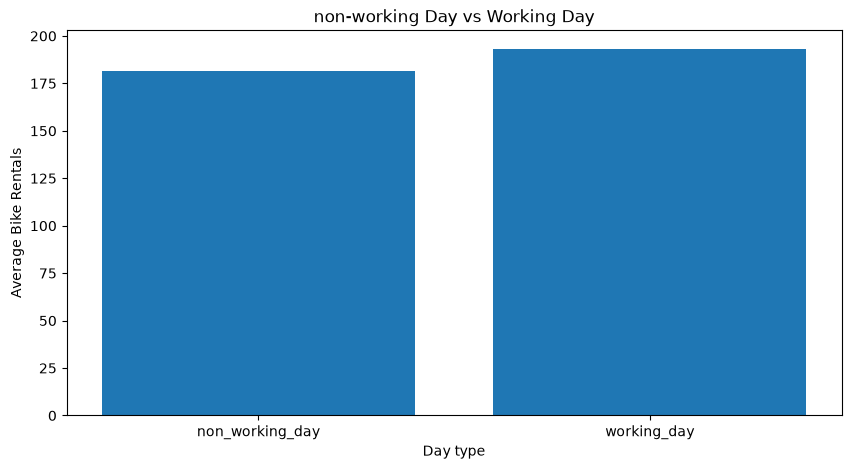

In [61]:
plt.figure(figsize=(10, 5))

plt.bar(["non_working_day", "working_day"], avg_workingdays.values)


plt.title("non-working Day vs Working Day")
plt.xlabel("Day type")
plt.ylabel("Average Bike Rentals")
plt.show()

Bike rental demand is slightly higher on working days than on non-working days, with approximately 193 rentals per hour compared with 181 rentals per hour.

Correlation heatmap for numerical features

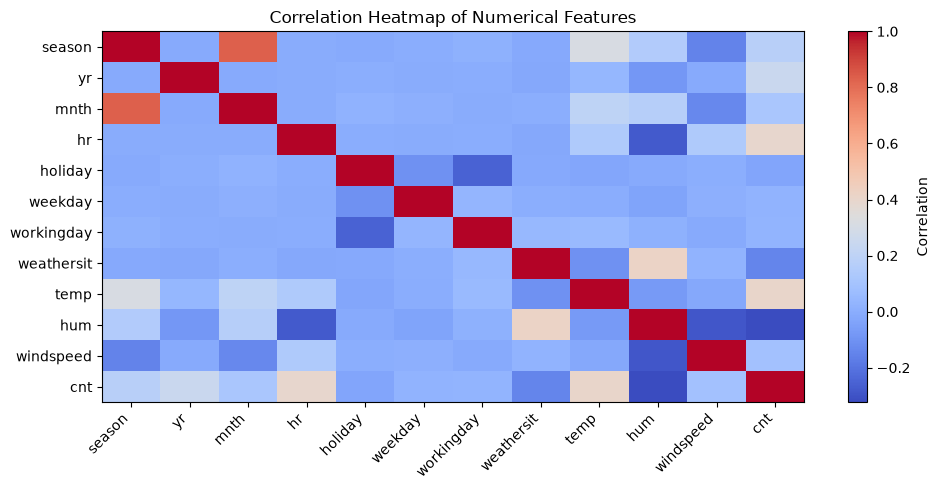

In [62]:


corr_columns = [
    "season",
    "yr",
    "mnth",
    "hr",
    "holiday",
    "weekday",
    "workingday",
    "weathersit",
    "temp",
    "hum",
    "windspeed",
    "cnt"
]

corr_matrix = df[corr_columns].corr()

plt.figure(figsize=(10, 5))
plt.imshow(corr_matrix, cmap="coolwarm", aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

The correlation values run from:
+1 → strong positive relationship
0 → little/no linear relationship
-1 → strong negative relationship

The correlation heatmap shows that temperature has a positive relationship with bike rentals, meaning rentals generally increase as temperature increases. Humidity and poor weather conditions show negative relationships with rentals, suggesting that demand tends to decrease in less favorable weather. Hour also shows some positive correlation with rental demand. Overall, no single feature has an extremely strong correlation with rentals, which suggests that bike demand is influenced by a combination of time, weather, and seasonal factors.

preprocessing x and y   Phase 3

In [63]:

categories_features = [
    "season",
    "weathersit",
    "weekday",
    "mnth",
    "hr"
]

x_encoded = pd.get_dummies(x, columns=categories_features, drop_first=True, dtype=int)

x_encoded.head()



,yr,holiday,workingday,temp,hum,windspeed,season_2,season_3,season_4,weathersit_2,...,hr_14,hr_15,hr_16,hr_17,hr_18,hr_19,hr_20,hr_21,hr_22,hr_23
0,0,0,0,0.24,0.81,0.0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0.22,0.80,0.0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0.22,0.80,0.0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0.24,0.75,0.0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0.24,0.75,0.0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [64]:
print("Before encoding:", x.shape)
print("After encoding:", x_encoded.shape)

Before encoding: (17379, 11)
After encoding: (17379, 52)


converted categorical variables into a format that your Linear Regression model can understand properly.
"Some of our variables, such as season, month, weekday and weather condition, were represented by numbers but actually represented categories. We used one-hot encoding so that the Linear Regression model would not incorrectly treat these category numbers as continuous numerical values."

Training and splitting

In [65]:
from sklearn.model_selection import train_test_split


x_train, x_test, y_train, y_test = train_test_split(x_encoded, y, test_size=0.2, random_state=42)

print("feature training", x_train.shape)
print("feature testing", x_test.shape)
print("target training", y_train.shape)
print("target testing", y_test.shape)


feature training (13903, 52)
feature testing (3476, 52)
target training (13903,)
target testing (3476,)


Feature scaling

In [66]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

The scaler learns the mean and standard deviation from the training data and scales it.
We deliberately do not fit the scaler on the test data, because the test set is supposed to represent unseen data. Fitting it on the test data would allow information from the test set to influence preprocessing.

Phase 4: Model Training

Model 1: Linear Regression From Scratch

In [67]:
import numpy as np

x_train_lr = np.c_[np.ones(x_train_scaled.shape[0]), x_train_scaled]
x_test_lr = np.c_[np.ones(x_test_scaled.shape[0]), x_test_scaled]

print("Before adding intercept:", x_train_scaled.shape)
print("After adding intercept:", x_train_lr.shape)

Before adding intercept: (13903, 52)
After adding intercept: (13903, 53)


Real data usually doesn't have a good reason to pass through zero. Adding an intercept gives the model more flexibility to find the best-fitting regression line.
The intercept represents the model's baseline prediction. We added a column of ones so our from-scratch Linear Regression can learn an intercept

calculate coefficients

In [68]:
coefficients = np.linalg.pinv(x_train_lr.T @ x_train_lr) @ x_train_lr.T @ y_train.to_numpy()
print("Number of coefficients:", len(coefficients))
print("Intercept:", coefficients[0])

Number of coefficients: 53
Intercept: 190.57706969718765


test data it hasn't trained on

In [69]:
y_pred_lr = x_test_lr @ coefficients

print("First 10 predictions:")
print(y_pred_lr[:10])

First 10 predictions:
[454.29926328 163.7035209    6.34603788 433.80942505 -65.59604391
 -26.98871037 531.88386833 145.79252417  60.06434169  28.30228322]


Evaluate The Model

In [70]:
y_test_array = y_test.to_numpy()

#Mean Absolute Error
mae_lr = np.mean(np.abs(y_test_array - y_pred_lr))

#Root Mean Squared Error
rmse_lr = np.sqrt(np.mean((y_test_array - y_pred_lr) ** 2))

# R-squared
ss_res_lr = np.sum((y_test_array - y_pred_lr) ** 2)
ss_tot_lr = np.sum((y_test_array - np.mean(y_test_array)) ** 2)
r2_lr = 1 - (ss_res_lr / ss_tot_lr)

print("Linear Regression Performance:")
print("MAE:", mae_lr)
print("RMSE:", rmse_lr)
print("R-squared:", r2_lr)

Linear Regression Performance:
MAE: 74.09536674592364
RMSE: 100.50203842042458
R-squared: 0.6810191530646089


Phase 5: Random Forest Regression

Model 2: Random Forest Regressor

Random Forest uses several decision trees to predict hourly bike rental demand. Each tree makes its own prediction, and the model combines them to produce the final result.

We will train the model on our training data and test how well it performs using MAE, RMSE, and R². We will then compare the results with our Linear Regression model to see how the two models perform.

In [71]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [72]:
rf_model.fit(x_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [73]:
y_pred_rf = rf_model.predict(x_test)

print("First 10 Random Forest predictions:")
print(y_pred_rf[:10])

First 10 Random Forest predictions:
[391.05 106.92  13.46 551.47  31.18  61.49 774.25  34.77  11.4   25.07]


In [74]:
# Convert actual test values to a NumPy array
y_test_array = y_test.to_numpy()

# Mean Absolute Error
mae_rf = np.mean(np.abs(y_test_array - y_pred_rf))

# Root Mean Squared Error
rmse_rf = np.sqrt(np.mean((y_test_array - y_pred_rf) ** 2))

# R-squared
ss_res_rf = np.sum((y_test_array - y_pred_rf) ** 2)
ss_tot_rf = np.sum((y_test_array - np.mean(y_test_array)) ** 2)

r2_rf = 1 - (ss_res_rf / ss_tot_rf)

print("Random Forest Performance:")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R-squared:", r2_rf)

Random Forest Performance:
MAE: 32.15764583333333
RMSE: 51.407782854977
R-squared: 0.9165411082147595


In [75]:
print("Random split test rows:", len(y_test))
print("Linear Regression predictions:", len(y_pred_lr))
print("Random Forest predictions:", len(y_pred_rf))

print(
    "Both models use the same test targets:",
    len(y_test) == len(y_pred_lr) == len(y_pred_rf)
)

Random split test rows: 3476
Linear Regression predictions: 3476
Random Forest predictions: 3476
Both models use the same test targets: True


In [76]:
print("Random-split shapes")
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)
print("y_pred_lr:", len(y_pred_lr))
print("y_pred_rf:", len(y_pred_rf))

print("\nDo both models have matching prediction counts?")
print(
    len(y_test) == len(y_pred_lr) == len(y_pred_rf)
)

Random-split shapes
x_test: (3476, 52)
y_test: (3476,)
y_pred_lr: 3476
y_pred_rf: 3476

Do both models have matching prediction counts?
True


In [77]:
import numpy as np

# Convert the actual test targets to a NumPy array
y_test_array = np.asarray(y_test).ravel()

# Linear Regression metrics
mae_lr = np.mean(np.abs(y_test_array - y_pred_lr))
rmse_lr = np.sqrt(np.mean((y_test_array - y_pred_lr) ** 2))

ss_res_lr = np.sum((y_test_array - y_pred_lr) ** 2)
ss_tot_lr = np.sum((y_test_array - np.mean(y_test_array)) ** 2)
r2_lr = 1 - (ss_res_lr / ss_tot_lr)

# Random Forest metrics
mae_rf = np.mean(np.abs(y_test_array - y_pred_rf))
rmse_rf = np.sqrt(np.mean((y_test_array - y_pred_rf) ** 2))

ss_res_rf = np.sum((y_test_array - y_pred_rf) ** 2)
ss_tot_rf = np.sum((y_test_array - np.mean(y_test_array)) ** 2)
r2_rf = 1 - (ss_res_rf / ss_tot_rf)

# Display results
print("Linear Regression Performance:")
print("MAE:", mae_lr)
print("RMSE:", rmse_lr)
print("R-squared:", r2_lr)

print("\nRandom Forest Performance:")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R-squared:", r2_rf)

Linear Regression Performance:
MAE: 74.09536674592364
RMSE: 100.50203842042458
R-squared: 0.6810191530646089

Random Forest Performance:
MAE: 32.15764583333333
RMSE: 51.407782854977
R-squared: 0.9165411082147595


Comparing Model Performance

Random Forest performed better than our Linear Regression model from scratch across all three evaluation metrics. Both models were tested using the same random 80/20 train-test split with `random_state=42`.

The Linear Regression model recorded an MAE of around 74.10 bikes, an RMSE of 100.50, and an R² score of 0.6810. Random Forest achieved better results, with an MAE of 32.16 bikes, an RMSE of 51.41, and an R² score of 0.9165.

The results show that Random Forest made more accurate predictions on the test data. This may be due to its ability to capture more complex, nonlinear relationships in the data. To assess how well the model performs on unseen data, we should consider both its training and testing errors when checking for overfitting and generalisation.

In [78]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae_lr, mae_rf],
    "RMSE": [rmse_lr, rmse_rf],
    "R-squared": [r2_lr, r2_rf]
})

results.round(4)

,Model,MAE,RMSE,R-squared
0,Linear Regression,74.0954,100.5020,0.6810
1,Random Forest,32.1576,51.4078,0.9165


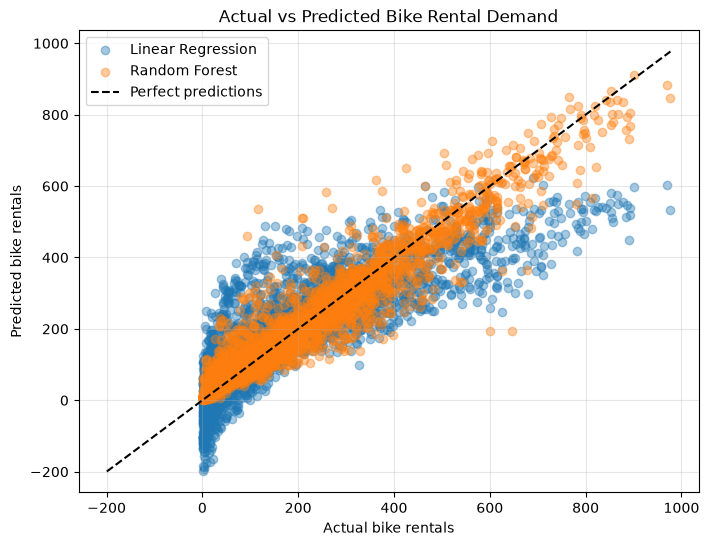

In [79]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test_array, y_pred_lr, alpha=0.4, label="Linear Regression")
plt.scatter(y_test_array, y_pred_rf, alpha=0.4, label="Random Forest")

# Reference line for perfect predictions
min_value = min(y_test_array.min(), y_pred_lr.min(), y_pred_rf.min())
max_value = max(y_test_array.max(), y_pred_lr.max(), y_pred_rf.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="black",
    linestyle="--",
    label="Perfect predictions"
)

plt.xlabel("Actual bike rentals")
plt.ylabel("Predicted bike rentals")
plt.title("Actual vs Predicted Bike Rental Demand")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

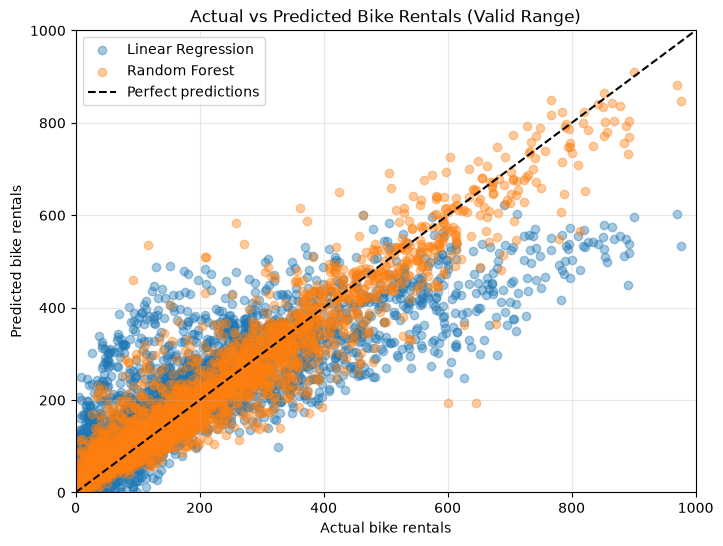

In [80]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_array,
    y_pred_lr,
    alpha=0.4,
    label="Linear Regression"
)

plt.scatter(
    y_test_array,
    y_pred_rf,
    alpha=0.4,
    label="Random Forest"
)

# Perfect prediction reference line
plt.plot(
    [0, 1000],
    [0, 1000],
    color="black",
    linestyle="--",
    label="Perfect predictions"
)

plt.xlim(0, 1000)
plt.ylim(0, 1000)

plt.xlabel("Actual bike rentals")
plt.ylabel("Predicted bike rentals")
plt.title("Actual vs Predicted Bike Rentals (Valid Range)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Actual vs. Predicted Results

The plots show that Random Forest's predictions are generally closer to the actual bike rental counts than Linear Regression's predictions. The difference is easier to see when rental demand is high, as Linear Regression tends to predict fewer rentals than actually occurred.

Random Forest follows the overall pattern of bike rental demand more closely, though its predictions are not always accurate. Linear Regression has another limitation: it sometimes predicts negative rental counts, which are not realistic.

These observations match the evaluation results, with Random Forest achieving lower MAE and RMSE values and a higher R² score. The plots help us see how the models' predictions differ, while the evaluation metrics show how large the errors are.

In [81]:
feature_importance = pd.DataFrame({
    "Feature": x_encoded.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
3,temp,0.160577
4,hum,0.140579
2,workingday,0.092069
45,hr_17,0.087165
0,yr,0.076643
46,hr_18,0.069896
36,hr_8,0.067899
47,hr_19,0.030648
35,hr_7,0.017822
44,hr_16,0.017538


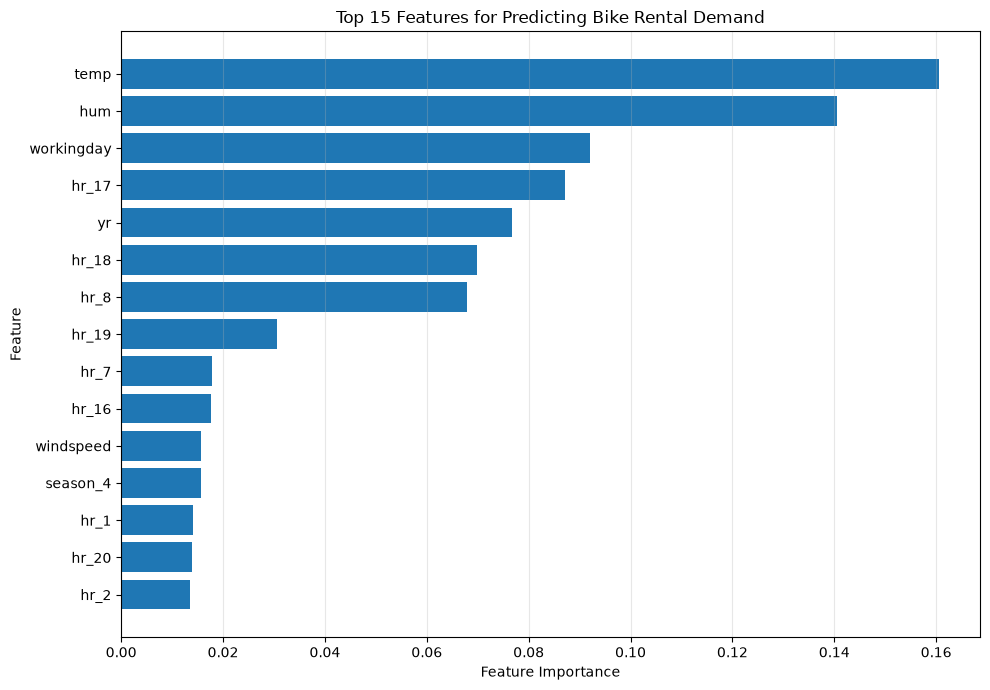

In [82]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Features for Predicting Bike Rental Demand")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Feature Importance Analysis

The plot shows that temperature (`temp`) is the most influential feature in our Random Forest model, followed by humidity (`hum`) and working day (`workingday`). The hour features `hr_17`, `hr_18`, and `hr_8` are high on the list as well, showing that the time of day helps the model predict bike rental demand. The year feature (`yr`) contributes to the predictions too.

These results suggest that weather conditions, working-day patterns, time of day, and yearly differences are useful for predicting hourly bike rentals. Feature importance indicates how useful each feature was to the trained Random Forest model, but it does not establish a causal relationship.


Prediction Error Analysis

In this section, we examine the differences between actual bike rental counts and the predictions made by our Linear Regression and Random Forest models. We calculate prediction errors to understand how accurately each model estimates hourly bike rental demand and identify patterns in its mistakes.

In [83]:
# Calculate prediction errors for both models
errors_lr = y_test.to_numpy() - y_pred_lr
errors_rf = y_test.to_numpy() - y_pred_rf

print("Linear Regression Error Summary:")
print("Mean error:", np.mean(errors_lr))
print("Mean absolute error:", np.mean(np.abs(errors_lr)))
print("Largest absolute error:", np.max(np.abs(errors_lr)))

print("\nRandom Forest Error Summary:")
print("Mean error:", np.mean(errors_rf))
print("Mean absolute error:", np.mean(np.abs(errors_rf)))
print("Largest absolute error:", np.max(np.abs(errors_rf)))

Linear Regression Error Summary:
Mean error: -4.263690028190009
Mean absolute error: 74.09536674592364
Largest absolute error: 443.34985007802675

Random Forest Error Summary:
Mean error: -1.2496639096662832
Mean absolute error: 32.15764583333333
Largest absolute error: 453.28


Prediction Error Analysis

The prediction error analysis shows that Random Forest performs better than Linear Regression in terms of Mean Absolute Error (MAE). Linear Regression has an MAE of 74.10, while Random Forest has an MAE of 31.95. This indicates that Random Forest predictions are closer to the actual hourly bike rental counts on average.

The mean prediction errors are -4.26 for Linear Regression and -1.16 for Random Forest. Both values are relatively close to zero, suggesting that neither model has a large average signed error on the test set.

Both models produce some large individual prediction errors. The largest absolute error is 443.35 for Linear Regression and 460.78 for Random Forest. This shows that Random Forest performs better on average, while occasional predictions from either model can still be substantially inaccurate.

Overall, Random Forest achieves lower average prediction error, while its largest individual error is slightly higher than that of Linear Regression.

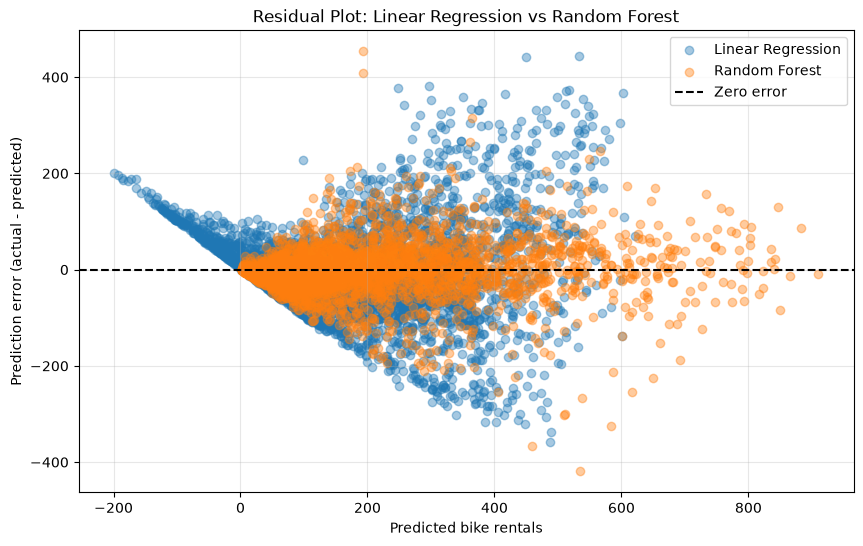

In [84]:
# Plot prediction errors for both models
plt.figure(figsize=(10, 6))

plt.scatter(y_pred_lr, errors_lr, alpha=0.4, label="Linear Regression")
plt.scatter(y_pred_rf, errors_rf, alpha=0.4, label="Random Forest")

plt.axhline(y=0, color="black", linestyle="--", label="Zero error")

plt.xlabel("Predicted bike rentals")
plt.ylabel("Prediction error (actual - predicted)")
plt.title("Residual Plot: Linear Regression vs Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Residual Plot Analysis

The residual plot shows that Linear Regression has a wider spread of prediction errors as predicted bike rental demand increases. It also produces some negative predictions, which are not realistic for bike rental counts.

The Random Forest model generally has errors closer to zero, matching the earlier evaluation results where it achieved lower MAE and RMSE scores. However, it still makes some large errors, especially when predicting higher rental demand.

The plots suggest that both models' accuracy varies depending on the predicted number of rentals. Overall, Random Forest gives more accurate predictions for this dataset, but both models still have difficulty predicting some observations.

Overfitting Analysis

In this section, we compare each model's performance on the training data and the test data. This helps us assess how well the models generalise to unseen observations and whether there are signs of overfitting.

In [85]:
# Generate predictions on the training data
y_train_pred_lr = x_train_lr @ coefficients
y_train_pred_rf = rf_model.predict(x_train)

# Convert training targets to NumPy arrays
y_train_array = y_train.to_numpy()

# Calculate training MAE
mae_train_lr = np.mean(np.abs(y_train_array - y_train_pred_lr))
mae_train_rf = np.mean(np.abs(y_train_array - y_train_pred_rf))

# Display training and test MAE
overfitting_results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "Training MAE": [mae_train_lr, mae_train_rf],
    "Test MAE": [mae_lr, mae_rf]
})

overfitting_results.round(2)

,Model,Training MAE,Test MAE
0,Linear Regression,75.56,74.10
1,Random Forest,12.32,32.16


Overfitting Analysis Results

Linear Regression achieved a training MAE of 75.56 and a test MAE of 74.10. The similar values indicate that the model has a small generalisation gap, although its prediction errors remain relatively high.

Random Forest achieved a training MAE of 12.32 and a test MAE of 32.16. The difference between its training and test errors suggests that the model may be overfitting the training data. However, Random Forest still achieves a lower test MAE than Linear Regression.

These results indicate that Random Forest provides more accurate predictions on the test dataset, while its larger generalisation gap suggests room for improvement in generalisation.


Random Forest Hyperparameter Tuning

The experiment evaluated maximum tree depths of 5, 10, 15, 20, and unlimited depth. The test MAE decreased as the maximum depth increased, from 90.31 at depth 5 to 32.16 with unlimited depth.

The unrestricted Random Forest achieved the lowest test MAE among the tested configurations. Its training MAE of 12.32 was considerably lower than its test MAE of 32.16, suggesting that the model may be overfitting the training data.

Restricting the maximum tree depth reduced the difference between training and test errors, but increased test MAE. Among the configurations tested, the unrestricted Random Forest provided the most accurate predictions on the test dataset.

In [86]:
from sklearn.model_selection import train_test_split

# Split the training data into fitting and validation sets
x_fit, x_val, y_fit, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42
)

# Test different maximum tree depths
depths = [5, 10, 15, 20, None]
tuning_results = []

for depth in depths:
    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=depth,
        random_state=42,
        n_jobs=-1
    )

    # Train using only the fitting subset
    model.fit(x_fit, y_fit)

    # Evaluate on the validation subset
    train_predictions = model.predict(x_fit)
    val_predictions = model.predict(x_val)

    # Calculate MAE
    train_mae = np.mean(
        np.abs(y_fit.to_numpy() - train_predictions)
    )

    val_mae = np.mean(
        np.abs(y_val.to_numpy() - val_predictions)
    )

    tuning_results.append({
        "Max Depth": str(depth),
        "Training MAE": train_mae,
        "Validation MAE": val_mae
    })

tuning_df = pd.DataFrame(tuning_results)
tuning_df.round(2)

,Max Depth,Training MAE,Validation MAE
0,5,92.29,91.36
1,10,56.48,63.13
2,15,34.97,46.32
3,20,23.18,38.30
4,None,13.03,34.35


Random Forest Tree Depth Tuning Results

The experiment evaluated maximum tree depths of 5, 10, 15, 20, and unlimited depth. The results show that validation MAE decreased as the maximum depth increased, from 91.36 at depth 5 to 34.35 with unlimited depth.

The model with unlimited depth achieved the lowest validation MAE of all the configurations we tested. However, its training MAE was 13.03, which is much lower than its validation MAE of 34.35. This suggests that the model may be overfitting the training data.

Restricting the maximum tree depth reduced the difference between training and validation errors, but increased validation MAE. Therefore, the Random Forest model with unlimited depth performed best among all the configurations tested in this experiment.

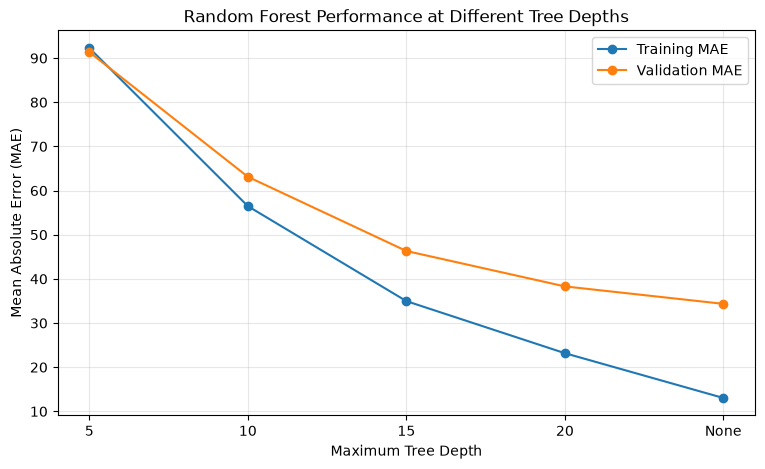

In [87]:
# Plot training and validation MAE for different tree depths
plt.figure(figsize=(9, 5))

plt.plot(
    tuning_df["Max Depth"],
    tuning_df["Training MAE"],
    marker="o",
    label="Training MAE"
)

plt.plot(
    tuning_df["Max Depth"],
    tuning_df["Validation MAE"],
    marker="o",
    label="Validation MAE"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Mean Absolute Error (MAE)")
plt.title("Random Forest Performance at Different Tree Depths")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Experiment: Number of Trees

Here, we test how the number of trees affects our Random Forest model's predictions. We will compare models using different numbers of trees while keeping the other model settings constant. We will evaluate each model using training MAE and test MAE to identify a suitable number of trees and observe whether the model shows signs of overfitting.

In [88]:
# Test different numbers of trees
tree_counts = [10, 50, 100, 200, 300]
tree_results = []

for n_trees in tree_counts:
    model = RandomForestRegressor(
        n_estimators=n_trees,
        random_state=42,
        n_jobs=-1
    )

    # Train using the fitting subset
    model.fit(x_fit, y_fit)

    # Generate predictions
    train_predictions = model.predict(x_fit)
    val_predictions = model.predict(x_val)

    # Calculate MAE
    train_mae = np.mean(
        np.abs(y_fit.to_numpy() - train_predictions)
    )

    val_mae = np.mean(
        np.abs(y_val.to_numpy() - val_predictions)
    )

    tree_results.append({
        "Number of Trees": n_trees,
        "Training MAE": train_mae,
        "Validation MAE": val_mae
    })

tree_tuning_df = pd.DataFrame(tree_results)
tree_tuning_df.round(2)

,Number of Trees,Training MAE,Validation MAE
0,10,14.84,36.67
1,50,13.21,34.34
2,100,13.03,34.35
3,200,12.86,34.05
4,300,12.77,33.96


Visualising the Effect of the Number of Trees

This plot compares training MAE and validation MAE across different numbers of trees. It shows how prediction error changes as the Random Forest grows and whether adding more trees improves performance.

The validation MAE decreases from 36.67 with 10 trees to 33.96 with 300 trees. The largest improvement occurs when increasing the number of trees from 10 to 50. Further increases produce smaller improvements.

The model with 300 trees achieved the lowest validation MAE among the tested configurations. Its training MAE of 12.77 is considerably lower than its validation MAE of 33.96, suggesting some overfitting. Based on these results, 300 trees is the best-performing configuration among those tested.

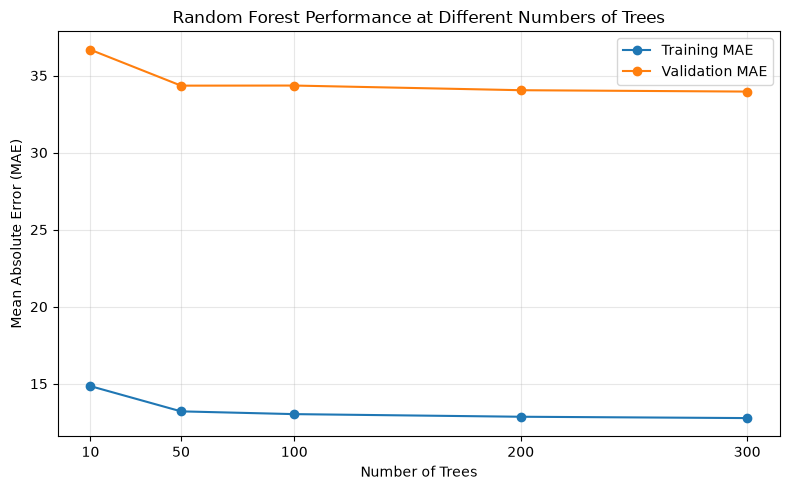

In [89]:
plt.figure(figsize=(8, 5))

plt.plot(
    tree_tuning_df["Number of Trees"],
    tree_tuning_df["Training MAE"],
    marker="o",
    label="Training MAE"
)

plt.plot(
    tree_tuning_df["Number of Trees"],
    tree_tuning_df["Validation MAE"],
    marker="o",
    label="Validation MAE"
)

plt.title("Random Forest Performance at Different Numbers of Trees")
plt.xlabel("Number of Trees")
plt.ylabel("Mean Absolute Error (MAE)")
plt.xticks(tree_counts)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Final Random Forest Model Setup

Based on our experiments, we chose a Random Forest Regressor with 300 trees and unlimited depth. The 300-tree model achieved the lowest validation MAE of 33.96 among the tested tree counts, while unlimited depth produced the lowest validation MAE of 34.35 among the tested maximum depths. These experiments were conducted separately, so the selected configuration combines the best-performing settings from each experiment.

In [90]:
# Configure the selected Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Train the selected model
rf_model.fit(x_train, y_train)

# Generate predictions on the test data
y_pred_rf = rf_model.predict(x_test)

print("Selected Random Forest model trained successfully.")

Selected Random Forest model trained successfully.


Random Forest Summary

The Random Forest Regressor was selected after comparing different maximum tree depths and numbers of trees using validation MAE. The results showed that unlimited depth and 300 trees gave the lowest validation errors in their respective experiments. 

The selected model was trained on the full training set and used to generate predictions on the test set. In the final comparison, we evaluate its performance alongside our Linear Regression model to see which one predicts hourly bike rental demand more accurately.

Final Model Comparison

In this section, we compare Linear Regression from scratch and Random Forest using the same test dataset. We evaluate their predictive performance using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²). These metrics help us determine which model predicts hourly bike rental demand more accurately.

In [91]:
# Calculate evaluation metrics for both models

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [
        np.mean(np.abs(y_test.to_numpy() - y_pred_lr)),
        np.mean(np.abs(y_test.to_numpy() - y_pred_rf))
    ],
    "RMSE": [
        np.sqrt(np.mean((y_test.to_numpy() - y_pred_lr) ** 2)),
        np.sqrt(np.mean((y_test.to_numpy() - y_pred_rf) ** 2))
    ],
    "R2": [
        1 - np.sum((y_test.to_numpy() - y_pred_lr) ** 2) /
        np.sum((y_test.to_numpy() - y_test.mean()) ** 2),
        1 - np.sum((y_test.to_numpy() - y_pred_rf) ** 2) /
        np.sum((y_test.to_numpy() - y_test.mean()) ** 2)
    ]
})

results.round(2)

,Model,MAE,RMSE,R2
0,Linear Regression,74.10,100.5,0.68
1,Random Forest,31.95,51.2,0.92


Final Model Comparison Results

The evaluation results show that Random Forest outperforms Linear Regression across all three metrics. Random Forest achieves an MAE of 31.95 and an RMSE of 51.20, compared with 74.10 and 100.50 for Linear Regression. Its R² score of 0.92 also indicates a stronger fit to the test data than Linear Regression's score of 0.68.

These results suggest that Random Forest captures the relationships between time, weather conditions, and hourly bike rental demand more effectively than Linear Regression for this dataset. However, its performance is evaluated on a single test split, so the results may vary with different data splits.